### Fotoforensik – Lösung Schritt für Schritt

*32. Bundeswettbewerb Informatik (2013), 1. Runde, Aufgabe 4*

Ein Mitarbeiter hat sich in der Kaffeepause selbst fotografiert, um zu dokumentieren, wie toll er mit der Kaffeekanne jonglieren kann. Leider klappte das aber nicht, und die Kaffeekanne zerbrach, was auf dem Foto zu erkennen ist. Da das Foto mit einem Smartphone aufgenommen wurde, wurde es zudem sofort automatisch auf den Server hochgeladen.

Jetzt fragt sich die Chefin, wer die Kaffeekanne zerbrochen hat. Der Übeltäter meldet sich nicht, weil er sich seines Missgeschicks zu sehr schämt. Er soll aber gar nicht bestraft werden; die Chefin stellt sich nur aus akademischem Interesse die Frage, ob anhand des gemachten Bildes die zugehörige Kamera bestimmt werden könnte. Alle Mitarbeiter haben einige Bilder auf der Firmenwebseite veröffentlicht, die alle in der gleichen Auflösung vorliegen.

#### Aufgabe 4

Enthält ein solches Bild einen eindeutigen „Fingerabdruck“ seiner Kamera? Können kameraspezifische Unterschiede in der Lichtempfindlichkeit der individuellen Pixel des CMOS-Sensors jeder Kamera zu statistisch signifikanten Eigenheiten führen? Gehe dieser Frage nach! Es stehen Dir neben dem Tatfoto auch eine Menge Fotografien zur Verfügung, die fünf einzelnen Kameras zugeordnet sind. Welche dieser Kameras gehört dem erfolglosen Kaffeekannenjongleur?

**Zu den Beispieldaten:** `Kanne.ppm` (das Tatfoto) und fünf Kameras mit je 4 bis 5 Fotos (`K1Bild1.ppm` bis `K5Bild5.ppm`, zusammen 24 Fotos), alle 2048 × 1536 Pixel. Die Fotos sind zu groß für das Repo (jedes etwa 33 MB als Text). Sie liegen als ZIP-Archive auf https://bwinf.de/bundeswettbewerb/32/1/ (`Kanne.ppm.zip`, `Kamera1.zip` bis `Kamera5.zip`). Dieses Notebook entwickelt das Verfahren deshalb an **selbst erzeugten kleinen Bildern**, bei denen wir den „Sensor“ selbst festlegen und die richtige Antwort kennen. Am Ende steht eine Funktion, die mit den echten Fotos läuft, wenn du sie in den Ordner `beispieldaten` entpackst; die Ergebnisse für die echten Fotos habe ich vorab berechnet und trage sie ein.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Fingerabdruck durch Mittelung:** Eine Messung, die für sich im Rauschen untergeht, wird deutlich, wenn man viele Messungen übereinanderlegt und mittelt: Das Zufällige (jedes Foto anders) hebt sich auf, das Gleichbleibende (der Sensor) bleibt übrig.
- **Glätten und Abziehen:** Zieht man von einem Bild eine geglättete Version ab, bleiben nur die feinen Abweichungen, das **Rauschen**. Der **Median** der Nachbarn glättet, ohne Kanten zu verwischen.
- **Korrelation:** Ein Zahlenwert zwischen −1 und 1, wie ähnlich zwei Muster sind (Pixel für Pixel verglichen). Nahe 0 heißt: kein Zusammenhang.
- **Gegenprobe (Leave-one-out):** Ein Verfahren, das neue Bilder zuordnen soll, prüft man an Bildern, deren Kamera man kennt: Das Bild weglassen, den Fingerabdruck aus den übrigen bilden, zuordnen, vergleichen.

**Nützliche Bibliotheken und Funktionen**
- **numpy:** `np.array` (Bilder als Zahlentabellen), Rechnen mit ganzen Tabellen auf einmal (`bild - glatt`), `np.median(..., axis=0)`, `np.pad` (Rand auffüllen), `.mean()`, `.sum()`, `.ravel()`, `np.random.default_rng(zahl)` (reproduzierbarer Zufall).
- **matplotlib** (`plt.imshow`) zur Anzeige von Bildern.

## Die Idee

Ein CMOS-Sensor besteht aus Millionen Pixeln, und keine zwei Pixel sind exakt gleich empfindlich. Dieser kleine, **bei jedem Foto gleiche** Fehler jedes Pixels (Fachwort: *fixed pattern noise* bzw. *PRNU*) ist der Fingerabdruck der Kamera. Dazu kommt bei jedem Foto neues, **zufälliges** Rauschen, und natürlich das eigentliche Motiv. Ein Foto ist also ungefähr

> **Foto = Motiv + Fingerabdruck der Kamera + Zufallsrauschen**

Das Motiv ist fast überall „glatt“ (benachbarte Pixel sind ähnlich), der Fingerabdruck und das Zufallsrauschen nicht. Wir gehen so vor:

1. **Rauschen herausziehen:** Bild minus geglättetes Bild (hier: Median der 3×3 Pixel um jedes Pixel). Übrig bleiben Fingerabdruck und Zufallsrauschen.
2. **Fingerabdruck einer Kamera:** Die Rauschbilder aller Fotos dieser Kamera mitteln. Das Zufallsrauschen mittelt sich heraus, der Fingerabdruck bleibt.
3. **Zuordnung:** Vom Tatfoto ebenfalls das Rauschen bestimmen und mit jedem der fünf Fingerabdrücke **korrelieren**. Die Kamera mit der größten Korrelation ist die Quelle.

Einfache Kenngrößen wie der mittlere Farbwert eines Bildes taugen nicht: Sie hängen vom Motiv ab, nicht von der Kamera. Das zeigen wir am Ende an den echten Fotos.

## Schritt 1: Das Bildformat PPM einlesen

Die Fotos liegen im Format **PPM** (Typ P3, reiner Text): Die erste Zeile ist `P3`, dann folgen Breite und Höhe, dann der größte Farbwert (255), dann für jedes Pixel drei Zahlen (rot, grün, blau), Pixel für Pixel von links nach rechts und Zeile für Zeile. Alle Zahlen sind durch Leerzeichen oder Zeilenwechsel getrennt, es genügt also `split()`. Die Funktion macht daraus eine numpy-Tabelle mit Form (Höhe, Breite, 3). Probe an einem winzigen Bild aus 2 × 2 Pixeln:

In [ ]:
import numpy as np


def lese_ppm_text(text):
    """Bild aus dem Text einer P3-PPM-Datei: Tabelle mit Form (Höhe, Breite, 3)."""
    teile = text.split()
    assert teile[0] == 'P3'
    breite = int(teile[1])
    hoehe = int(teile[2])
    # teile[3] ist der größte Farbwert (255), danach kommen die Farbwerte
    zahlen = np.array(teile[4:4 + hoehe * breite * 3], dtype=np.int32)
    return zahlen.reshape(hoehe, breite, 3)


def lese_ppm_datei(pfad):
    with open(pfad) as datei:
        return lese_ppm_text(datei.read())


mini = lese_ppm_text("P3\n2 2\n255\n255 0 0  0 255 0\n0 0 255  10 20 30")
print(mini.shape)
print(mini[0, 1], mini[1, 1])      # Zeile 0 Spalte 1: grün, Zeile 1 Spalte 1: (10, 20, 30)

(2, 2, 3)
[  0 255   0] [10 20 30]


## Schritt 2: Das Rauschen eines Bildes

Für jedes Pixel bilden wir den **Median** der 3 × 3 Pixel um es herum (das Pixel selbst eingeschlossen). Der Median ist der mittlere Wert der sortierten neun Zahlen. Am Bildrand fehlen Nachbarn; wir wiederholen dort den Randwert (`np.pad(..., mode='edge')`). Dann verschieben wir das Bild neunmal um einen Pixel nach oben/unten/links/rechts, legen die neun Tabellen übereinander (`np.stack`) und nehmen den Median entlang der neuen Achse. Das Rauschen ist Bild minus Median.

Warum der **Median** und nicht der Mittelwert? An einer Kante (links dunkel, rechts hell) liegt der Mittelwert zwischen beiden und verwischt die Kante. Der Median nimmt den Wert einer der beiden Seiten, die Kante bleibt scharf und gilt dann nicht als „Rauschen“. Kleines Beispiel mit einer Kante zwischen Spalte 3 und 4 (10 links, 50 rechts) und zwei verrauschten Pixeln (13 und 52):

In [ ]:
def glaetten_median(bild):
    """Median der 3x3-Umgebung jedes Pixels (Bild als 2D-Tabelle), am Rand wird der Randwert wiederholt."""
    hoehe, breite = bild.shape
    rand = np.pad(bild, 1, mode='edge')
    verschoben = []
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            verschoben.append(rand[1 + di:1 + di + hoehe, 1 + dj:1 + dj + breite])
    return np.median(np.stack(verschoben), axis=0)


def glaetten_mittel(bild):
    """Zum Vergleich: Mittelwert der 3x3-Umgebung."""
    hoehe, breite = bild.shape
    rand = np.pad(bild, 1, mode='edge')
    summe = 0
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            summe = summe + rand[1 + di:1 + di + hoehe, 1 + dj:1 + dj + breite]
    return summe / 9


klein = np.array([[10, 10, 10, 50, 50],
                  [10, 13, 10, 50, 52],
                  [10, 10, 10, 50, 50],
                  [10, 10, 10, 50, 50]])
print('Rauschen mit Median:')
print(klein - glaetten_median(klein))
print('Rauschen mit Mittelwert (gerundet):')
print(np.round(klein - glaetten_mittel(klein), 1))

Rauschen mit Median:
[[0. 0. 0. 0. 0.]
 [0. 3. 0. 0. 2.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]]
Rauschen mit Mittelwert (gerundet):
[[ -0.3  -0.3 -13.7  13.1  -0.4]
 [ -0.3   2.7 -13.7  13.1   1.6]
 [ -0.3  -0.3 -13.7  13.1  -0.4]
 [  0.    0.  -13.3  13.3   0. ]]


Mit dem **Median** bleiben genau die beiden verrauschten Pixel übrig (3 und 2), alles andere, auch die Kante, ist 0. Mit dem **Mittelwert** sieht man dagegen an der Kante Werte um ±13: Die Kante würde als Rauschen gezählt, und das Motiv würde den Fingerabdruck verfälschen.

Für ein Farbbild machen wir das für jeden der drei Farbkanäle getrennt:

In [ ]:
def rauschen(bild):
    """Rauschbild (gleiche Form wie das Bild): Bild minus 3x3-Median, je Farbkanal."""
    bild = bild.astype(np.float32)
    if bild.ndim == 2:
        return bild - glaetten_median(bild)
    ergebnis = np.empty_like(bild)
    for kanal in range(bild.shape[2]):
        ergebnis[:, :, kanal] = bild[:, :, kanal] - glaetten_median(bild[:, :, kanal])
    return ergebnis


print(rauschen(mini).shape, rauschen(klein).shape)

(2, 2, 3) (4, 5)


## Schritt 3: Eine Testwelt mit fünf Kameras

Da die echten Fotos nicht im Repo liegen, bauen wir eine kleine Welt, in der wir die Wahrheit kennen. Jede der fünf Kameras bekommt einen **festen Fingerabdruck** (für jedes Pixel ein kleiner fester Fehler, zufällig gewählt, aber für diese Kamera immer derselbe). Jedes Foto besteht aus einem Motiv (ein Helligkeitsverlauf mit einigen Rechtecken, bei jedem Foto anders), dem Fingerabdruck der Kamera und neuem Zufallsrauschen. Die Bilder sind 80 × 60 Pixel groß und grau (ein Zahlenwert je Pixel), das reicht für die Idee.

(Vereinfachung: Bei echten Sensoren ist der Fehler eine kleine *prozentuale* Abweichung der Empfindlichkeit, also umso größer, je heller das Pixel. Hier addieren wir ihn einfach.)

In [ ]:
HOEHE, BREITE = 60, 80


def motiv(zufall):
    """Ein beliebiges 'Motiv': Helligkeitsverlauf plus einige helle oder dunkle Rechtecke."""
    bild = np.linspace(80, 160, BREITE)[None, :] + np.linspace(0, 40, HOEHE)[:, None]
    for _ in range(6):
        i = zufall.integers(0, HOEHE - 10)
        j = zufall.integers(0, BREITE - 10)
        bild[i:i + zufall.integers(5, 25), j:j + zufall.integers(5, 25)] += zufall.integers(-60, 60)
    return bild


# Fingerabdruck jeder Kamera: fester Fehler je Pixel (Streuung 2), für jede Kamera mit eigenem Startwert
FINGERABDRUCK = {kamera: np.random.default_rng(1000 + kamera).normal(0, 2.0, (HOEHE, BREITE)) for kamera in range(1, 6)}


def foto(kamera, zufall):
    """Ein simuliertes Foto: Motiv + Fingerabdruck der Kamera + Zufallsrauschen (Streuung 2), ganzzahlig 0..255."""
    bild = motiv(zufall) + FINGERABDRUCK[kamera] + zufall.normal(0, 2.0, (HOEHE, BREITE))
    return np.clip(np.rint(bild), 0, 255).astype(np.int32)


zufall = np.random.default_rng(42)
fotos = {kamera: [foto(kamera, zufall) for _ in range(5)] for kamera in range(1, 6)}      # je 5 Fotos
tatfoto = foto(3, zufall)           # das "Tatfoto": heimlich von Kamera 3
print({kamera: len(liste) for kamera, liste in fotos.items()}, tatfoto.shape)

{1: 5, 2: 5, 3: 5, 4: 5, 5: 5} (60, 80)


Ein Foto und sein Rauschbild (rechts, stark verstärkt dargestellt; die Kanten des Motivs sind im Rauschbild verschwunden):

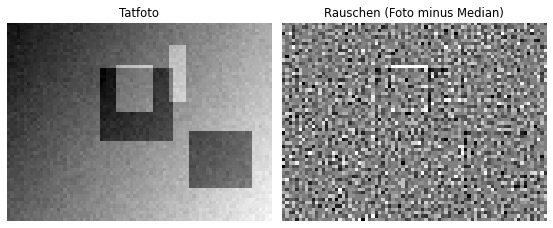

In [ ]:
import matplotlib.pyplot as plt

bild_paar, achsen = plt.subplots(1, 2, figsize=(8, 3.2))
achsen[0].imshow(tatfoto, cmap='gray')
achsen[0].set_title('Tatfoto')
achsen[1].imshow(rauschen(tatfoto), cmap='gray', vmin=-8, vmax=8)
achsen[1].set_title('Rauschen (Foto minus Median)')
for a in achsen:
    a.axis('off')
plt.tight_layout()
plt.show()

## Schritt 4: Fingerabdruck und Ähnlichkeit

Der Fingerabdruck einer Kamera ist der Mittelwert der Rauschbilder ihrer Fotos. Die **Korrelation** zweier Tabellen: Von beiden den Mittelwert abziehen, dann Pixel für Pixel multiplizieren und summieren, und durch die Längen beider Tabellen teilen. Dann liegt das Ergebnis immer zwischen −1 und 1, und es ist egal, wie „laut“ ein Rauschbild insgesamt ist.

In [ ]:
def fingerabdruck_von(liste):
    """Mittelwert der Rauschbilder einer Liste von Fotos."""
    summe = 0
    for bild in liste:
        summe = summe + rauschen(bild)
    return summe / len(liste)


def korrelation(a, b):
    """Korrelation zweier gleich großer Tabellen (Wert zwischen -1 und 1)."""
    a = a.ravel() - a.mean()
    b = b.ravel() - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))


def bestimme_kamera(bild, abdruecke):
    """Korrelation des Rauschens von bild mit jedem Fingerabdruck (Dictionary Kamera -> Wert) und die beste Kamera."""
    r = rauschen(bild)
    werte = {kamera: korrelation(r, abdruck) for kamera, abdruck in abdruecke.items()}
    beste = max(werte, key=werte.get)
    return beste, werte


abdruecke = {kamera: fingerabdruck_von(liste) for kamera, liste in fotos.items()}
beste, werte = bestimme_kamera(tatfoto, abdruecke)
for kamera in sorted(werte):
    print('Kamera %d: %.3f' % (kamera, werte[kamera]))
print('Das Tatfoto stammt von Kamera', beste)

Kamera 1: 0.007
Kamera 2: 0.017
Kamera 3: 0.354
Kamera 4: 0.013
Kamera 5: -0.009
Das Tatfoto stammt von Kamera 3


Die Korrelation mit dem Fingerabdruck von Kamera 3 liegt bei 0.35, die übrigen vier Werte liegen um 0 (zwischen -0.01 und 0.02). Die Zuordnung ist eindeutig und stimmt: Kamera 3 war die Quelle.

**Warum mitteln?** Ein einzelnes Rauschbild enthält neben dem Fingerabdruck das Zufallsrauschen dieses einen Fotos. Je mehr Fotos man mittelt, desto reiner wird der Fingerabdruck. Wir prüfen es, indem wir das Tatfoto mit dem Fingerabdruck aus nur 1, 2, 3, 4 und 5 Fotos von Kamera 3 vergleichen:

In [ ]:
for anzahl in range(1, 6):
    ab = fingerabdruck_von(fotos[3][:anzahl])
    print('%d Foto(s): Korrelation mit Kamera 3 = %.3f' % (anzahl, korrelation(rauschen(tatfoto), ab)))

1 Foto(s): Korrelation mit Kamera 3 = 0.255
2 Foto(s): Korrelation mit Kamera 3 = 0.288
3 Foto(s): Korrelation mit Kamera 3 = 0.317
4 Foto(s): Korrelation mit Kamera 3 = 0.343
5 Foto(s): Korrelation mit Kamera 3 = 0.354


## Schritt 5: Gegenprobe mit allen Fotos (Leave-one-out)

Eine einzige richtige Zuordnung kann Glück sein. Wir prüfen das Verfahren deshalb an **jedem** bekannten Foto: Das Foto wird aus seiner Kamera herausgenommen, die fünf Fingerabdrücke werden aus den übrigen Fotos gebildet, dann ordnen wir zu und vergleichen mit der bekannten Kamera. (Das Foto selbst darf nicht im Fingerabdruck stecken, sonst wäre die Korrelation geschönt.)

In [ ]:
def gegenprobe(fotos):
    """Ordnet jedes bekannte Foto mit Fingerabdrücken aus den übrigen Fotos zu; liefert (Treffer, Gesamtzahl, Fehlzuordnungen)."""
    treffer = 0
    gesamt = 0
    fehler = []
    for kamera in fotos:
        for k in range(len(fotos[kamera])):
            abdruecke = {}
            for kam2 in fotos:
                uebrige = [bild for n, bild in enumerate(fotos[kam2]) if not (kam2 == kamera and n == k)]
                abdruecke[kam2] = fingerabdruck_von(uebrige)
            beste, _ = bestimme_kamera(fotos[kamera][k], abdruecke)
            gesamt += 1
            if beste == kamera:
                treffer += 1
            else:
                fehler.append((kamera, k + 1, beste))
    return treffer, gesamt, fehler


print(gegenprobe(fotos))

(25, 25, [])


Alle 25 simulierten Fotos werden richtig zugeordnet. In der Simulation ist es allerdings einfach: Der Fingerabdruck ist stark (Streuung 2) im Vergleich zum Zufallsrauschen (ebenfalls 2), und die Motive haben wenig Struktur. Wie es bei den echten Fotos aussieht, zeigt Schritt 7.

## Schritt 6: Wie sicher ist das? (Zufallsbaseline)

Zwei Rauschmuster, die **nichts miteinander zu tun haben**, haben trotzdem eine Korrelation, die nicht genau 0 ist, sondern zufällig schwankt. Bei `n` unabhängigen Werten ist die typische Größe dieser Schwankung etwa `1 / Wurzel(n)`. Eine Korrelation ist erst dann ein Beleg, wenn sie **viel größer** ist als diese Schwankung. Ausprobiert für unsere Bildgröße (4800 Werte), mit 2000 Paaren zufälliger Muster:

In [ ]:
zufall = np.random.default_rng(7)
n = HOEHE * BREITE
zufallswerte = [korrelation(zufall.normal(size=n), zufall.normal(size=n)) for _ in range(2000)]
print('Streuung der Zufallskorrelation: %.4f' % np.std(zufallswerte))
print('1 / Wurzel(n)                  : %.4f' % (1 / np.sqrt(n)))

Streuung der Zufallskorrelation: 0.0143
1 / Wurzel(n)                  : 0.0144


Die gemessene Streuung stimmt mit `1 / Wurzel(n)` überein. Für unsere Simulation liegt sie bei etwa 0,014, also ist ein Wert von 0.35 weit entfernt davon. Bei den echten Fotos mit 2048 × 1536 × 3 = 9 437 184 Werten ist `1 / Wurzel(n)` etwa 0,0003 (die Werte sind in Wirklichkeit nicht alle unabhängig, das ist also eine grobe Größenordnung).

## Schritt 7: Die echten Fotos

Die folgende Funktion macht dasselbe wie die Simulation, aber mit den echten PPM-Dateien: Für jede Kamera werden die Rauschbilder ihrer Fotos aufsummiert (nicht alle gleichzeitig im Speicher halten, ein Rauschbild hat 3 × 2048 × 1536 Zahlen) und durch die Anzahl geteilt, dann wird das Rauschen des Tatfotos mit den fünf Fingerabdrücken korreliert. Lege die entpackten Dateien so ab: `beispieldaten/Kanne.ppm`, `beispieldaten/Kamera1/K1Bild1.ppm`, ... (`Kamera5/K5Bild5.ppm`). Wegen der Dateigröße und der vielen Rechnungen dauert der Lauf auf einem normalen Rechner einige Minuten und ist für JupyterLite im Browser nicht gedacht.

In [ ]:
import glob
import os


def auswerten(ordner):
    """Korrelation des Tatfotos (ordner/Kanne.ppm) mit den Fingerabdrücken der Kameras 1 bis 5 (ordner/KameraN/*.ppm)."""
    abdruecke = {}
    for kamera in range(1, 6):
        dateien = sorted(p for p in glob.glob('%s/Kamera%d/**/*.ppm' % (ordner, kamera), recursive=True) if os.path.isfile(p))
        summe = 0
        for datei in dateien:
            summe = summe + rauschen(lese_ppm_datei(datei))
        abdruecke[kamera] = summe / len(dateien)
        print('Kamera', kamera, ':', len(dateien), 'Fotos')
    kanne = [p for p in glob.glob('%s/**/Kanne.ppm' % ordner, recursive=True) if os.path.isfile(p)][0]
    return bestimme_kamera(lese_ppm_datei(kanne), abdruecke)


if os.path.exists('beispieldaten/Kanne.ppm'):
    beste_echt, werte_echt = auswerten('beispieldaten')
    for kamera in sorted(werte_echt):
        print('Kamera %d: %.4f' % (kamera, werte_echt[kamera]))
    print('Das Tatfoto stammt von Kamera', beste_echt)
else:
    print('Die großen Fotos liegen nicht in beispieldaten/ (Quelle: https://bwinf.de/bundeswettbewerb/32/1/).')

Die großen Fotos liegen nicht in beispieldaten/ (Quelle: https://bwinf.de/bundeswettbewerb/32/1/).


Mit den echten Fotos kommt bei mir heraus (Median-Rauschen, drei Farbkanäle, Fingerabdruck aus allen Fotos der Kamera):

| Kamera | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Korrelation mit dem Tatfoto | −0,0003 | −0,0005 | **0,0120** | 0,0004 | 0,0005 |

**Kamera 3 ist die Quelle**, wie in den Lösungshinweisen. Der Abstand ist deutlich: Kamera 3 liegt rund 25-mal höher als der nächste Wert und etwa 35-mal über der Zufallsschwankung von rund 0,0003 aus Schritt 6. Die absoluten Werte sind klein, weil auf den echten Fotos der Fingerabdruck sehr viel schwächer ist als das Motiv und das Zufallsrauschen, und weil der Median das Motiv nicht ganz entfernt.

**Wie zuverlässig ist das?** Gegenprobe (Leave-one-out) an allen 24 bekannten Fotos: **23 werden richtig zugeordnet**. Ein Foto (`K1Bild3`) wird fälschlich Kamera 4 zugeordnet; die beiden Werte liegen dort nahe beieinander (jeweils um 0,002). Das passt zu den Werten in der Tabelle: Die Korrelation des richtigen Fingerabdrucks liegt je nach Foto zwischen 0,001 und 0,022, die der falschen zwischen −0,001 und 0,002. Das Tatfoto mit 0,012 liegt klar im sicheren Bereich der richtigen Zuordnungen.

**Wie viele Fotos braucht man für den Fingerabdruck?** Das Tatfoto gegen nur *ein* Foto von Kamera 3 verglichen, ergibt je nach Foto 0,004 bis 0,012. Mit allen fünf Fotos 0,012. Mittelung hilft also, aber schon ein einzelnes Foto zeigt Kamera 3 vorn.

**Reicht ein Ausschnitt?** Nicht zuverlässig. Bei Ausschnitten von 64 × 64 Pixeln (links oben und in der Bildmitte) war Kamera 3 nicht eindeutig vorn. Bei 512 × 512 Pixeln lag die Korrelation mit Kamera 3 links oben bei 0,049, in der Bildmitte aber nur bei 0,002. Der Fingerabdruck ist über das Bild ungleich stark. Man sollte das ganze Bild nehmen.

## Und wenn man es sich einfach macht?

Die Lösungshinweise warnen: Wer nur den **Mittelwert aller Farbwerte** vergleicht, liegt eher falsch. Das stimmt, wie Zahlen der echten Fotos zeigen:

- Mittlere Farbe (rot, grün, blau) des Tatfotos: (115,9; 113,9; 97,1). Die Fotos *einer* Kamera schwanken viel stärker als der Unterschied zwischen Kameras, z. B. Kamera 1 von (104,5; 119,3; 91,9) bis (112,0; 131,8; 137,8). Das Motiv bestimmt den Mittelwert, nicht die Kamera.
- Der **mittlere Farbabstand benachbarter Pixel** (die Idee aus den Lösungshinweisen) liegt für das Tatfoto bei 8,8. Die Fotos der Kameras haben Werte von 15,8 bis 35,4 (Kamera 1), 6,3 bis 16,4 (Kamera 2), 7,4 bis 19,3 (Kamera 3), 6,5 bis 23,6 (Kamera 4) und 5,4 bis 13,5 (Kamera 5). Die 8,8 passen zu **vier** Kameras (2, 3, 4, 5); nur Kamera 1 ist ausgeschlossen. Als Entscheidung taugt das nicht. (Die Lösungshinweise nennen diese Kenngröße als mögliche einfachere Variante; mit meiner Fassung, Summe der Farbabweichungen in Rot, Grün und Blau zu den vier Nachbarn, unterscheidet sie die Kameras nicht.)

Beides sind **Kenngrößen eines ganzen Bildes**, die vom Motiv dominiert werden. Das Rauschverfahren dagegen vergleicht Pixel für Pixel, also das, was der Sensor festlegt.

In [ ]:
def mittelwert_farbe(bild):
    return bild.reshape(-1, 3).mean(axis=0)


def nachbarabstand(bild):
    """Mittlerer Farbabstand (Summe der Beträge der drei Farbunterschiede) zwischen waagerechten bzw. senkrechten Nachbarn."""
    g = bild.astype(np.float32)
    waagerecht = np.abs(g[:, 1:] - g[:, :-1]).sum(axis=2).mean()
    senkrecht = np.abs(g[1:] - g[:-1]).sum(axis=2).mean()
    return float((waagerecht + senkrecht) / 2)


# an einem kleinen Farbbild: Verlauf von schwarz nach weiß, links nach rechts
verlauf = np.zeros((2, 3, 3), dtype=np.int32)
verlauf[:, :, 0] = [[0, 10, 20], [0, 10, 20]]
print(mittelwert_farbe(verlauf), nachbarabstand(verlauf))

[10.  0.  0.] 5.0


## Zum Schluss: Geht das mit MiniZinc?

Technisch ja, **sinnvoll** ist es nicht. MiniZinc ist für Probleme gedacht, bei denen ein Solver etwas **suchen** muss (Zuordnungen, Pläne, Rätsel). Hier gibt es nichts zu suchen: Die Kamera folgt aus einer Rechnung (Skalarprodukte). Das Rauschen selbst (Median der Nachbarn) lässt sich in MiniZinc auch nicht schön ausdrücken, ich habe es deshalb in Python berechnet und MiniZinc nur den Vergleich mit den fünf Fingerabdrücken machen lassen. Ich habe es trotzdem gemessen, mit diesem Modell (`fotoforensik.mzn`): `r` ist das Rauschen des Tatfotos (als ganze Zahlen), `F[c]` die **Summe** der Rauschbilder der Kamera `c`. Die Güte einer Kamera ist das Skalarprodukt geteilt durch die Länge von `F[c]` (die Länge von `r` ist für alle gleich und kürzt sich heraus). Die Mittelwerte der Bilder ziehen wir hier nicht ab (das Rauschen hat ohnehin den Mittelwert nahe 0), es ist also eine vereinfachte Korrelation. `solve maximize` wählt dann die Kamera mit der größten Güte. Die Summen werden als `float` gerechnet, weil die Zwischenergebnisse die 32 Bit von Gecode überschreiten (Quadratsummen bis etwa 10^12):

```minizinc
int: K;                                         % Anzahl Kameras
int: H;                                         % Höhe
int: W;                                         % Breite
array[1..H, 1..W] of int: r;                    % Rauschen des Tatfotos
array[1..K, 1..H, 1..W] of int: F;              % Summe der Rauschbilder je Kamera (gleiche Skala)

array[1..K] of float: skalarprodukt = [ sum(i in 1..H, j in 1..W)(int2float(r[i, j]) * int2float(F[c, i, j])) | c in 1..K ];
array[1..K] of float: laenge2 = [ sum(i in 1..H, j in 1..W)(int2float(F[c, i, j]) * int2float(F[c, i, j])) | c in 1..K ];

var 1..K: kamera;
var float: guete = skalarprodukt[kamera] / sqrt(laenge2[kamera]);

solve maximize guete;
output ["Kamera \(kamera)\n"];
```

Die Datendatei erzeugt eine Python-Zelle aus unseren Rauschbildern (ganzzahlig gerundet). Bei der Simulation sind alle Kameras mit gleich vielen Fotos vertreten, deshalb sind die Summen direkt vergleichbar. Bei den echten Fotos haben vier Kameras fünf und eine vier Fotos; dort multipliziere ich jede Summe mit `60 / Anzahl der Fotos`, damit alle auf der Skala von 60 Fotos liegen.

In [ ]:
def als_dzn(tat, kameras):
    """MiniZinc-Daten: ganzzahliges Rauschen des Tatfotos und Summe der Rauschbilder je Kamera."""
    ganz = lambda t: np.rint(t).astype(int)
    h, b = tat.shape
    zahlen_r = ', '.join(str(x) for x in ganz(rauschen(tat)).ravel())
    summen = []
    for kamera in sorted(kameras):
        s = sum(ganz(rauschen(bild)) for bild in kameras[kamera])
        summen.append(', '.join(str(x) for x in s.ravel()))
    vorlage = 'K = %d;\nH = %d;\nW = %d;\nr = array2d(1..H, 1..W, [%s]);\nF = array3d(1..K, 1..H, 1..W, [%s]);\n'
    return vorlage % (len(kameras), h, b, zahlen_r, ', '.join(summen))


dzn_sim = als_dzn(tatfoto, fotos)
print('Länge der Datendatei in Zeichen:', len(dzn_sim))

Länge der Datendatei in Zeichen: 108475


Mit Gecode (MiniZinc IDE) kommt für die Simulation heraus:

**Ausgabe:**

```
Kamera 3
```

Das ist dieselbe Kamera wie in Python. Für die echten Fotos habe ich die Datendatei aus den gerundeten Grauwert-Rauschbildern (Summe der drei Farbwerte, Median darüber) erzeugt: Sie hat rund 70 MB (6 × 3 145 728 Zahlen). Gecode braucht dafür gut eine halbe Minute und gibt ebenfalls **Kamera 3** aus (die Skalarprodukte durch die Längen liegen bei −11,9; −4,4; **139,2**; −9,0; 7,3 für die Kameras 1 bis 5). Mit 32-Bit-Zahlen statt `float` bricht MiniZinc mit einem Überlauffehler ab, und CP-SAT stürzte bei der Ganzzahlfassung mit dieser Datenmenge ab. Ein Vorteil gegenüber Python ist das nicht: Das Modell schreibt nur eine Summe auf, die das Programm ohnehin ausrechnet, und der aufwendige Teil (Rauschen bestimmen) bleibt in Python. MiniZinc lohnt sich bei dieser Aufgabe nicht.

## Für Neugierige

- **Echte Sensoren** haben einen Fehler, der mit der Helligkeit wächst (eine kleine Abweichung in Prozent, englisch *PRNU*). Die Literatur gewichtet deshalb das Rauschen mit der Helligkeit und filtert besser als mit dem Median (Wavelets, Wiener-Filter). Das verbessert die Zuordnung, ist aber für diese Aufgabe nicht nötig.
- **JPEG-Kompression** zerstört viel vom feinen Rauschen. Hier liegen die Fotos als PPM ohne Kompression vor, bei Fotos aus dem Netz wird die Zuordnung deutlich schwerer.
- **Rotation, Zuschnitt, Skalierung** verschieben die Pixel gegenüber dem Fingerabdruck; dann müsste man die richtige Verschiebung suchen (Kreuzkorrelation). Die Aufgabe sagt, alle Bilder hätten dieselbe Auflösung, das ist hier nicht nötig.
- **Wie groß ist „deutlich“?** Wer eine Entscheidung wie „ist es überhaupt eine dieser Kameras?“ treffen will, braucht eine Schwelle, z. B. das Zehnfache der Zufallsschwankung `1 / Wurzel(n)`. Bei Kamera 3 ist diese Schwelle mit 0,0120 gegenüber etwa 0,0033 weit überschritten.